In [1]:
import zipfile
with zipfile.ZipFile("/content/data.zip", 'r') as zip_ref:
    zip_ref.extractall()

In [42]:
import os
import cv2
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [43]:
base_path = '/content/crop_dataset/crop_dataset'

In [44]:
images = []
labels = []

IMG_SIZE = 32

for class_folder in sorted(os.listdir(base_path)):
    class_path = os.path.join(base_path, class_folder)
    if not os.path.isdir(class_path):
        continue

    label = int(class_folder)

    for file in os.listdir(class_path):
        if file.lower().endswith(('.jpg', '.png')):
            img_path = os.path.join(class_path, file)
            image = cv2.imread(img_path)

            if image is None:
                continue

            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
            images.append(image)
            labels.append(label)

print(f"\nLoaded {len(images)} images from {len(set(labels))} classes.")


Loaded 26640 images from 43 classes.


In [45]:
X = np.array(images, dtype='float32') / 255.0
y = to_categorical(np.array(labels))

In [46]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Validation: {X_val.shape}")

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(y.shape[1], activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val)
)

Train: (21312, 32, 32, 3), Validation: (5328, 32, 32, 3)


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,979 (1.22 MB)

 Trainable params: 319,979 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 40s 110ms/step - accuracy: 0.2447 - loss: 2.8965 - val_accuracy: 0.8380 - val_loss: 0.6676
Epoch 2/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 25s 75ms/step - accuracy: 0.7515 - loss: 0.8516 - val_accuracy: 0.9383 - val_loss: 0.2757
Epoch 3/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 43s 81ms/step - accuracy: 0.8556 - loss: 0.4930 - val_accuracy: 0.9595 - val_loss: 0.1756
Epoch 4/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 41s 80ms/step - accuracy: 0.8867 - loss: 0.3908 - val_accuracy: 0.9747 - val_loss: 0.1274
Epoch 5/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 40s 78ms/step - accuracy: 0.9050 - loss: 0.3110 - val_accuracy: 0.9726 - val_loss: 0.1312
Epoch 6/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 42s 80ms/step - accuracy: 0.9171 - loss: 0.2685 - val_accuracy: 0.9803 - val_loss: 0.0926
Epoch 7/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 41s 79ms/step - accuracy: 0.9327 - loss: 0.2280 - val_accuracy: 0.9820 - val_loss: 0.0814
Epoch 8/15
333/333 ━━━━━━━━━━━━━━━━━━━━ 27s 82ms/step - accuracy: 0.9352 - loss: 0.2077 -

167/167 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
🧾 Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        30
           1       1.00      0.98      0.99       300
           2       0.99      0.99      0.99       300
           3       0.97      0.98      0.98       192
           4       1.00      1.00      1.00       264
           5       0.95      0.98      0.96       252
           6       1.00      1.00      1.00        60
           7       0.97      0.98      0.98       192
           8       1.00      0.97      0.99       192
           9       0.99      1.00      1.00       198
          10       1.00      1.00      1.00       270
          11       0.99      1.00      0.99       180
          12       1.00      1.00      1.00       282
          13       1.00      1.00      1.00       288
          14       1.00      1.00      1.00       108
          15       1.00      1.00      1.00        84
          16  

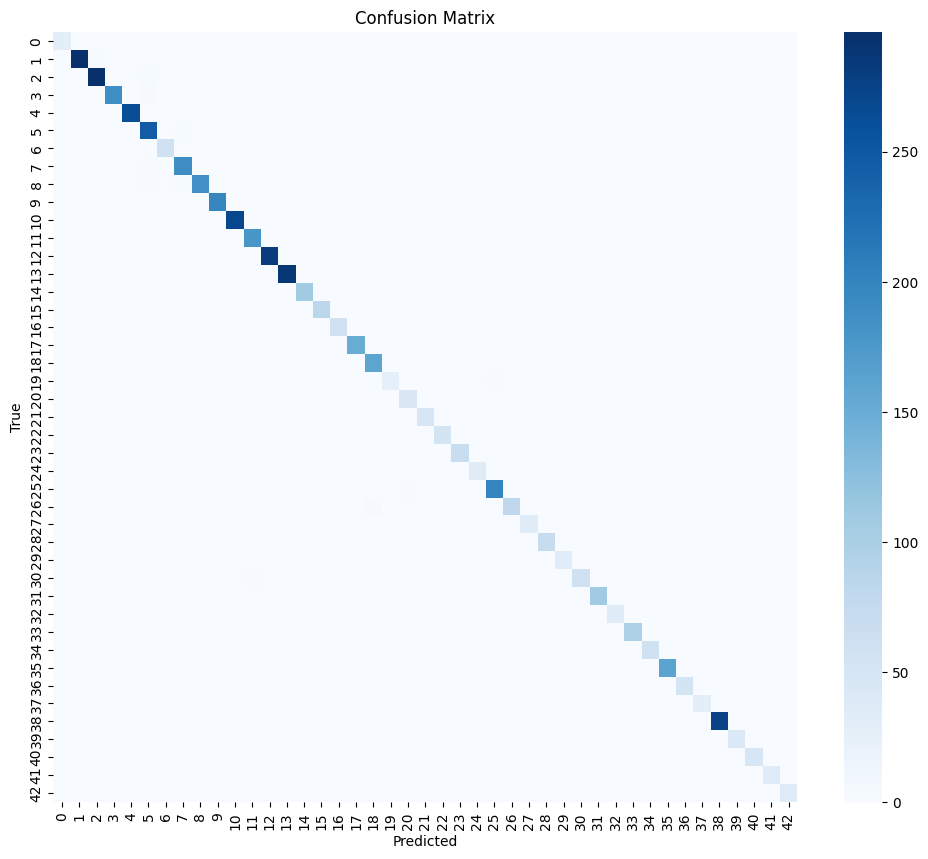

In [47]:
y_pred = model.predict(X_val)
y_pred_labels = np.argmax(y_pred, axis=1)
y_true_labels = np.argmax(y_val, axis=1)

print("🧾 Classification Report:")
print(classification_report(y_true_labels, y_pred_labels))

cm = confusion_matrix(y_true_labels, y_pred_labels)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=False, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()